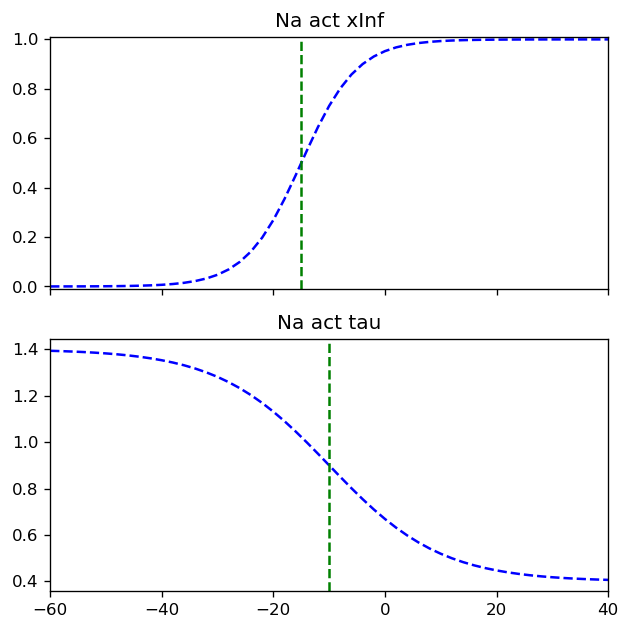

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interactive_output, HBox, VBox, Layout


def update_plot(vHalf, vK, tau0, tau1, th, tk):
    '''GEMINI'''
    vKi = 1.0/vK
    tkInv = 1.0/tk
    valRange = np.linspace(-80, 40, 200)
    gateData = genGate(vHalf, vKi, tau0, tau1, th, tkInv)
    
    xInf = sigmoid(valRange, gateData["vHalf"], gateData["vKi"], gateData["minOpenness"]) 
    xTau = gateData["tau0"] + gateData["tau1"] * sigmoid(valRange, gateData["th"], gateData["tkInv"], 0)

    fig, ax = plt.subplots(2, 1, figsize=(7, 5), dpi=110, sharex=True)
    
    # Top Plot: x_inf
    ax[0].plot(valRange, xInf, c="b", lw=2)
    ax[0].axvline(gateData["vHalf"], color="g", linestyle="--", alpha=0.7)
    ax[0].set_title("Steady State Openness ($x_{\\infty}$)")
    ax[0].set_ylabel("Open Probability")
    ax[0].set_ylim(-0.02, 1.02)
    ax[0].grid(True, linestyle=":", alpha=0.6)

    # Bottom Plot: tau
    ax[1].plot(valRange, xTau, c="r", lw=2)
    ax[1].axvline(gateData["th"], color="g", linestyle="--", alpha=0.7)
    ax[1].set_title("Time Constant ($\\tau$)")
    ax[1].set_ylabel("Tau (ms)")
    ax[1].set_xlabel("Voltage (mV)")
    ax[1].grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()

    

def examineChannelNormal(channel,ax=None,nSamples = 51):
    if ax is None:
        fig,ax = plt.subplots(3,3,figsize=(12,8), dpi=80)
        fig.suptitle(f"Channel: {channel['name']}, ion: {channel['ion']}")
    gateOpening = np.ones([nSamples])
    for i,(gate,gateData) in enumerate(channel["gates"].items()):
        if gate != "spikeGate":
            if gate == "CaGate":
                vr = np.linspace(0,1e-3,nSamples)
                xInf = examineGateNormal(gateData,vr,gate,[ax[0,i],ax[1,i]])
            else:
                valRange = np.linspace(-100,100,nSamples)
                xInf = examineGateNormal(gateData,valRange,gate,[ax[0,i],ax[1,i]])
                exponent = gateData["exponent"]
                gateOpening *= xInf**exponent

    ax[2,0].plot(valRange,gateOpening,c="orange",ls="--")
    plt.tight_layout()


    
def genGate(vHalf,vKi,tau0,tau1,th,tkInv,x0=0.0,exponent=1,minOpenness=0):
    return {"x":x0, "vHalf":vHalf,"vKi":vKi,"tau0":tau0,"tau1":tau1,"th":th,"tkInv":tkInv,"exponent":exponent,"minOpenness":minOpenness}

def genOpenGate():
    return genGate(-1000,1000,100,1000,0,0,x0=1)

def genSynapseGate(xt1,TS):
    xt0 = TS
    xt1 = xt1-xt0
    return genGate(0.5,100,xt0,xt1,0.5,-100)

def sigmoid(z,h,kInv,minOp):
    return minOp +  (1.0-minOp)/(1.0 + np.exp((h-z)*kInv))

def examineGateNormal(gateData,valRange,gateName,ax=None):
    xInf = sigmoid(valRange,gateData["vHalf"],gateData["vKi"],gateData["minOpenness"]) 
    xTau = gateData["tau0"] + gateData["tau1"]*sigmoid(valRange,gateData["th"],gateData["tkInv"],0)
    gRange = [min(valRange),max(valRange)]

    if ax is None:
        fig,ax = plt.subplots(2,1,figsize=(8,6), dpi=100)
    
    ax[0].plot(valRange,xInf,c="b",ls="--")
    ax[0].axvline(gateData["vHalf"],color="g",linestyle="--")
    ax[0].set_title(f"{gateName} xInf")
    ax[0].set_xlim(gRange)
    #x[0].set_ylabel("Gate opening")
    ax[0].set_ylim(-0.01,1.01)

    ax[1].plot(valRange,xTau,c="b",ls="--")
    ax[1].axvline(gateData["th"],color="g",linestyle="--")
    ax[1].set_title(f"{gateName} tau")
    #ax[1].set_ylabel("Time constant (ms)")
    ax[1].set_xlim(gRange)
    
    return xInf



Vhalf,Vk = -15,1/5
tau0,tau1 = 0.4,1
tauHalf,tauK = -10,-1/10

NaActivationGate = genGate(Vhalf,Vk,tau0,tau1,tauHalf,tauK,x0=0.0,exponent=3,minOpenness=0)
fig,ax = plt.subplots(2,1,figsize=(6,6),dpi=120,sharex=True)
examineGateNormal(NaActivationGate,np.linspace(-60,40,51),'Na act',ax=ax);

In [2]:
# --- Interactive Plotter Bridge ---
# This was done with Gemini


# --- Widget UI Layout Construction ---

style = {'description_width': 'initial'}
slider_layout = Layout(width='95%')

w_vHalf = widgets.FloatSlider(value=-15.0, min=-60.0, max=10.0, step=1.0, description='V Half (vHalf)', style=style, layout=slider_layout)
w_Ki = widgets.FloatSlider(value=5.0, min=-51.0, max=50.0, step=1.0, description='Inv Slope (vKi)', style=style, layout=slider_layout)
w_tau0 = widgets.FloatSlider(value=0.4, min=0.05, max=5.0, step=0.05, description='Base Tau (tau0)', style=style, layout=slider_layout)
w_tau1 = widgets.FloatSlider(value=1.0, min=0.0, max=10.0, step=0.1, description='Amp Tau (tau1)', style=style, layout=slider_layout)
w_th = widgets.FloatSlider(value=-10.0, min=-60.0, max=10.0, step=1.0, description='Tau Mid (th)', style=style, layout=slider_layout)
w_tk = widgets.FloatSlider(value=-10, min=-51.0, max=50.0, step=1.0, description='Tau Inv Slope (tkInv)', style=style, layout=slider_layout)

# Map UI controls directly to plotting parameters
ui_output = interactive_output(
    update_plot,  
    {'vHalf': w_vHalf, 'vK': w_Ki, 'tau0': w_tau0, 'tau1': w_tau1, 'th': w_th, 'tk': w_tk}
)

# Arrange controls into clean columns next to the canvas
left_box = VBox([w_vHalf, w_Ki, w_tau0], layout=Layout(width='50%'))
right_box = VBox([w_tau1, w_th, w_tk], layout=Layout(width='50%'))
controls_panel = HBox([left_box, right_box], layout=Layout(margin='0 0 10px 0'))

# Render the dashboard
display(VBox([controls_panel, ui_output]))

Here I am going to make a very simple sodium channel with an activation and inactivation gate.
Going to base it off Nav1.6 which is pretty common in the axon initial segment.
[Smith et al. 1998](https://doi.org/10.1523/jneurosci.18-16-06093.1998)

Activation Vhalf is about -25mV, with km of about 5mV
Inactivation Vhalf is about -75mV with a slope of about 7mV

Activation peak rate is about 0.1 to 0.4ms (we'll say 0.4)
Inactivation is rate is 0.5 to 2ms during upstroke
Rapid deactivation 

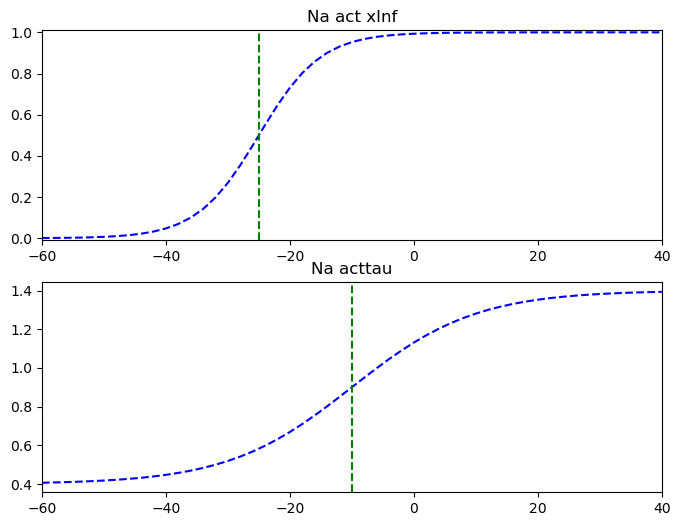